### Notebook 02: Stationary Hover Control

This notebook simulates the quadcopter maintaining a stationary hover at an altitude of 1 m for 120 seconds.

Unlike Notebook 01, which assumed perfect equilibrium, this simulation introduces small initial position and attitude errors. A proportional-derivative (PD) controller adjusts the four individual motor torques to return the drone to the desired hover position.

The simulation uses the same 16-state equations of motion from `drone_model.py`.

The goal is to verify that the quadcopter can maintain stable hover using rotor-speed-based control, satisfying ER2 and Performance Goal 1 (PG1).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, trapezoid

import drone_model as drone

hover_speed, hover_torque = drone.hover_conditions()

# Initial conditions
initial_state = np.zeros(16)

initial_state[0] = 0.15
initial_state[1] = -0.10
initial_state[2] = 0.90

initial_state[6] = np.radians(2)
initial_state[7] = np.radians(-2)

initial_state[12:16] = hover_speed

# Desired hover position
target_position = np.array([0.0, 0.0, 1.0])

simulation_time = 140
time_points = np.linspace(0, simulation_time, 1401)

print("Initial position:", initial_state[0:3])
print("Target position:", target_position)
print("Initial attitude:", np.degrees(initial_state[6:9]))

Initial position: [ 0.15 -0.1   0.9 ]
Target position: [0. 0. 1.]
Initial attitude: [ 2. -2.  0.]


#### Hover Control

The controller compares the drone's current position and velocity with the desired stationary hover.

A proportional-derivative (PD) controller uses position error and velocity to calculate the required acceleration:

$$
a_{x,d} = K_p(x_d-x)-K_dv_x
$$

$$
a_{y,d} = K_p(y_d-y)-K_dv_y
$$

For small angles near zero yaw, the desired roll and pitch are approximated by:

$$
\phi_d = -\frac{a_{y,d}}{g},
\qquad
\theta_d = \frac{a_{x,d}}{g}
$$

The vertical controller adjusts total thrust:

$$
T_d = m[g+K_{pz}(z_d-z)-K_{dz}v_z]
$$

The attitude controller calculates the roll, pitch, and yaw moments using angular errors and body angular velocities.

These desired thrust and moments are converted into four rotor speeds using the equations developed by the Design Engineer. Motor torques then accelerate or decelerate the rotors toward those speeds.

All drone motion is still generated through the four motor torques, as required by ER2.

In [2]:
# PD controller gains
KP_XY = 0.9
KD_XY = 1.6

KP_Z = 2.8
KD_Z = 2.6

KP_ANGLE = 16.0
KD_ANGLE = 7.0

KP_YAW = 8.0
KD_YAW = 5.0

# Motor control
MOTOR_GAIN = 25.0

# Preliminary motor limits
MAX_RPM = 6530
MAX_SPEED = MAX_RPM * 2 * np.pi / 60
MAX_TORQUE = 0.14

# Convert total thrust and body moments to rotor speeds
k = drone.THRUST_COEFF
b = drone.DRAG_COEFF
L = drone.ARM_LENGTH

mixing_matrix = np.array([
    [k, k, k, k],
    [0, L*k, 0, -L*k],
    [-L*k, 0, L*k, 0],
    [-b, b, -b, b]
])

def hover_controller(time, state):
    x, y, z = state[0:3]
    vx, vy, vz = state[3:6]
    roll, pitch, yaw = state[6:9]
    p, q, r = state[9:12]
    rotor_speeds = state[12:16]

    # Position control
    ax = KP_XY * (0 - x) - KD_XY * vx
    ay = KP_XY * (0 - y) - KD_XY * vy

    desired_roll = -ay / drone.GRAVITY
    desired_pitch = ax / drone.GRAVITY

    desired_roll = np.clip(desired_roll, -0.26, 0.26)
    desired_pitch = np.clip(desired_pitch, -0.26, 0.26)

    # Altitude control
    az = KP_Z * (1.0 - z) - KD_Z * vz

    total_thrust = drone.MASS * (
        drone.GRAVITY + az
    ) / (np.cos(roll) * np.cos(pitch))

    # Attitude control
    torque_x = drone.IX * (
        KP_ANGLE * (desired_roll - roll) - KD_ANGLE * p
    )

    torque_y = drone.IY * (
        KP_ANGLE * (desired_pitch - pitch) - KD_ANGLE * q
    )

    torque_z = drone.IZ * (
        KP_YAW * (0 - yaw) - KD_YAW * r
    )

    # Required collective thrust and body moments
    commands = np.array([
        total_thrust,
        torque_x,
        torque_y,
        torque_z
    ])

    # Calculate desired rotor speeds
    speed_squared = np.linalg.solve(mixing_matrix, commands)
    speed_squared = np.clip(speed_squared, 0, MAX_SPEED**2)
    desired_speeds = np.sqrt(speed_squared)

    # Motor torque controls rotor acceleration
    motor_torques = (
        drone.DRAG_COEFF * rotor_speeds**2
        + drone.ROTOR_INERTIA * MOTOR_GAIN *
        (desired_speeds - rotor_speeds)
    )

    motor_torques = np.clip(motor_torques, 0, MAX_TORQUE)

    return motor_torques

In [3]:
# Equations of motion with feedback control
def controlled_dynamics(time, state):
    motor_torques = hover_controller(time, state)
    return drone.drone_derivatives(time, state, motor_torques)

# Run simulation
solution = solve_ivp(
    controlled_dynamics,
    (0, simulation_time),
    initial_state,
    t_eval=time_points,
    rtol=1e-7,
    atol=1e-9,
    max_step=0.05
)

assert solution.success, solution.message

print("Solver successful:", solution.success)
print("Simulation duration:", solution.t[-1], "s")
print("Final position:", solution.y[0:3, -1])
print("Final attitude:", np.degrees(solution.y[6:9, -1]))

Solver successful: True
Simulation duration: 140.0 s
Final position: [-1.44289232e-14 -1.00406554e-15  1.00000000e+00]
Final attitude: [-3.14230612e-15 -2.83810549e-15 -1.34863943e-14]


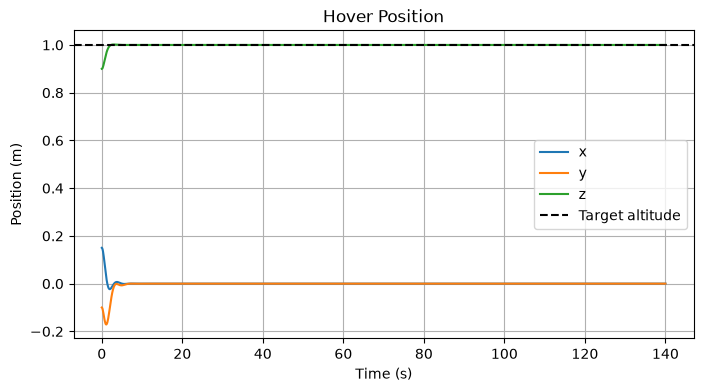

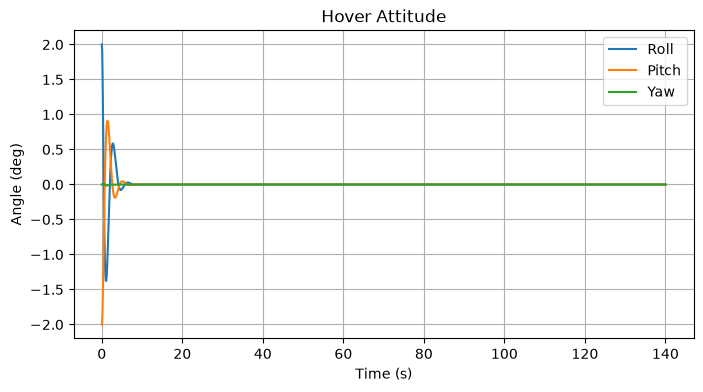

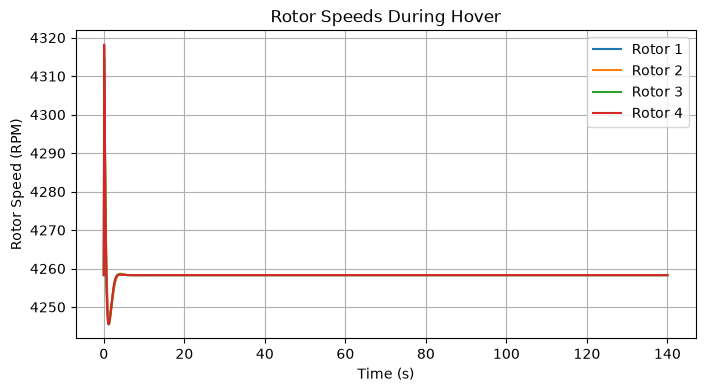

In [4]:
time = solution.t

x = solution.y[0]
y = solution.y[1]
z = solution.y[2]

roll = np.degrees(solution.y[6])
pitch = np.degrees(solution.y[7])
yaw = np.degrees(solution.y[8])

# Position
plt.figure(figsize=(8, 4))
plt.plot(time, x, label="x")
plt.plot(time, y, label="y")
plt.plot(time, z, label="z")
plt.axhline(1.0, color="black", linestyle="--", label="Target altitude")
plt.xlabel("Time (s)")
plt.ylabel("Position (m)")
plt.title("Hover Position")
plt.legend()
plt.grid()
plt.show()

# Attitude
plt.figure(figsize=(8, 4))
plt.plot(time, roll, label="Roll")
plt.plot(time, pitch, label="Pitch")
plt.plot(time, yaw, label="Yaw")
plt.xlabel("Time (s)")
plt.ylabel("Angle (deg)")
plt.title("Hover Attitude")
plt.legend()
plt.grid()
plt.show()

# Rotor speeds
plt.figure(figsize=(8, 4))

for i in range(4):
    rpm = solution.y[12+i] * 60 / (2*np.pi)
    plt.plot(time, rpm, label=f"Rotor {i+1}")

plt.xlabel("Time (s)")
plt.ylabel("Rotor Speed (RPM)")
plt.title("Rotor Speeds During Hover")
plt.legend()
plt.grid()
plt.show()

In [5]:
# Check the final 120 seconds
hover_time = time >= 20

position = solution.y[0:3, hover_time]
velocity = solution.y[3:6, hover_time]
attitude = solution.y[6:9, hover_time]

position_error = position - target_position[:, None]

max_position_error = np.max(
    np.linalg.norm(position_error, axis=0)
)

max_speed = np.max(
    np.linalg.norm(velocity, axis=0)
)

max_attitude_error = np.degrees(
    np.max(np.abs(attitude))
)

print("Maximum position error:", round(max_position_error, 4), "m")
print("Maximum speed:", round(max_speed, 4), "m/s")
print("Maximum attitude error:", round(max_attitude_error, 4), "deg")

hover_pass = (
    max_position_error < 0.05
    and max_speed < 0.05
    and max_attitude_error < 3.0
)

print("120-second hover test passed:", hover_pass)

# Power consumption
power = []

for i in range(len(time)):
    speeds = solution.y[12:16, i]
    power.append(drone.electrical_power(speeds))

power = np.array(power)

# Energy during the 120-second hover period
hover_energy = trapezoid(
    power[hover_time],
    time[hover_time]
) / 3600

# Energy including initial stabilization
total_energy = trapezoid(power, time) / 3600

usable_energy = (
    drone.BATTERY_VOLTAGE *
    drone.BATTERY_CAPACITY *
    (1 - drone.BATTERY_RESERVE)
)

print("Hover energy:", round(hover_energy, 3), "Wh")
print("Total simulation energy:", round(total_energy, 3), "Wh")
print("Usable battery energy:", round(usable_energy, 2), "Wh")
print("Energy requirement passed:", total_energy < usable_energy)

# Check motor speeds and input torques
motor_inputs = []

for i in range(len(time)):
    motor_inputs.append(
        hover_controller(time[i], solution.y[:, i])
    )

motor_inputs = np.array(motor_inputs)

print("Maximum rotor speed:", round(
    np.max(solution.y[12:16]) * 60 / (2*np.pi), 1
), "RPM")

print("Maximum motor torque:", round(
    np.max(motor_inputs), 4
), "Nm")

Maximum position error: 0.0 m
Maximum speed: 0.0 m/s
Maximum attitude error: 0.0 deg
120-second hover test passed: True
Hover energy: 4.781 Wh
Total simulation energy: 5.578 Wh
Usable battery energy: 44.4 Wh
Energy requirement passed: True
Maximum rotor speed: 4318.2 RPM
Maximum motor torque: 0.0597 Nm
